# Where Should Aid Go First? Segmenting 167 Countries by Need

**Scenario:** an aid organisation has a limited budget and wants a defensible, data-driven shortlist of countries in the greatest need.

**Data:** 9 socio-economic and health indicators for 167 countries: child mortality, exports, health spend, imports, income, inflation, life expectancy, fertility and GDP per capita.

**What this notebook does differently:**
1. Fixes the heavy skew in money-based indicators with log transforms *before* clustering, so a handful of very rich countries don't dominate the distances.
2. Chooses the number of clusters using **three independent signals**: silhouette score, Gaussian-mixture BIC, and **bootstrap stability** (do the same groups come back when the data is resampled?).
3. Doesn't stop at "cluster 2 = poor countries". It builds a transparent **need index** to rank countries *within* the high-need group into a priority list.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 21

df = pd.read_csv("../data/country_data.csv").set_index("country")
print(df.shape, "| missing:", int(df.isna().sum().sum()), "| duplicates:", int(df.index.duplicated().sum()))

(167, 9) | missing: 0 | duplicates: 0


## 1. The skew problem

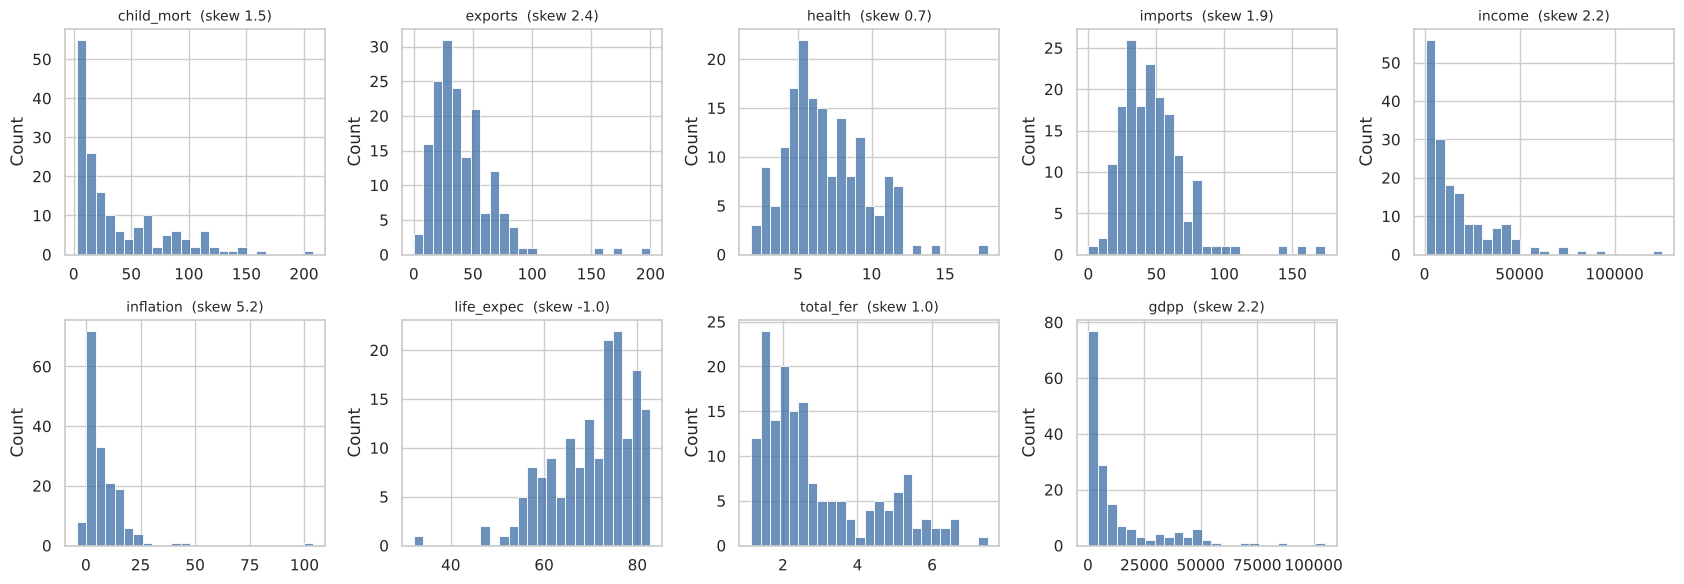

In [2]:
fig, axes = plt.subplots(2, 5, figsize=(17, 6))
for ax, col in zip(axes.flat, df.columns):
    sns.histplot(df[col], ax=ax, bins=25, color="#3b6ea5")
    ax.set_title(f"{col}  (skew {df[col].skew():.1f})", fontsize=10)
    ax.set_xlabel("")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

Income, GDP per capita, child mortality and inflation have long right tails. Standard scaling alone would let Qatar or Luxembourg stretch the income axis and squash every developing country into one corner.

Fix: `log1p` the strictly positive skewed indicators, and apply a sign-preserving log to inflation because it has negative values. After that, standardise everything.

In [3]:
skewed = ["child_mort", "exports", "imports", "income", "gdpp", "health", "total_fer"]
features = df.copy()
features[skewed] = np.log1p(features[skewed])
features["inflation"] = np.sign(features["inflation"]) * np.log1p(features["inflation"].abs())
print("Skew after transform:\n", features.skew().round(2).to_string())

Z = StandardScaler().fit_transform(features)

Skew after transform:
 child_mort    0.07
exports      -1.09
health       -0.23
imports      -1.82
income       -0.24
inflation    -0.49
life_expec   -0.97
total_fer     0.54
gdpp          0.01


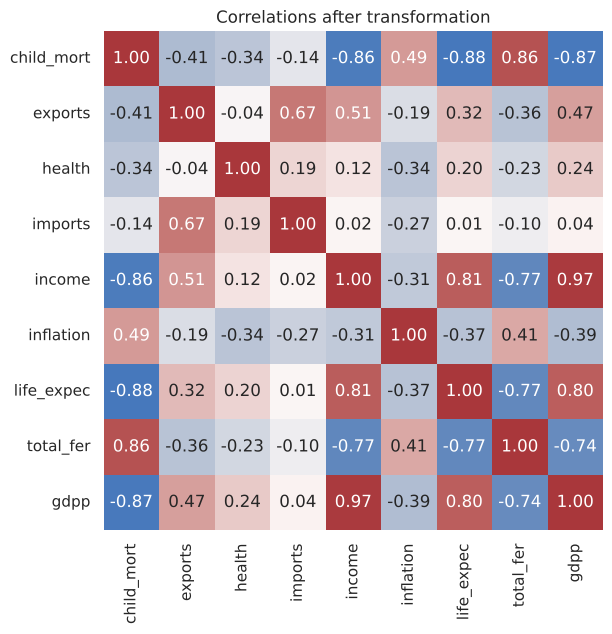

In [4]:
plt.figure(figsize=(8, 6.5))
sns.heatmap(features.corr(), annot=True, fmt=".2f", cmap="vlag", center=0, square=True, cbar=False)
plt.title("Correlations after transformation")
plt.tight_layout()
plt.show()

Child mortality, fertility, life expectancy, income and GDP per capita are tightly linked (|r| > 0.8). They describe one underlying "development" axis. Exports and imports form a second, "trade openness" axis. That shows up again in the PCA below.

## 2. How many groups? Three independent checks

In [5]:
def bootstrap_stability(k, n_boot=40):
    """Refit on bootstrap samples and compare labels on all countries with the full-data fit (ARI)."""
    base = KMeans(k, n_init=20, random_state=SEED).fit(Z).labels_
    rng = np.random.default_rng(SEED)
    scores = []
    for _ in range(n_boot):
        idx = rng.choice(len(Z), len(Z), replace=True)
        km = KMeans(k, n_init=10, random_state=int(rng.integers(1e6))).fit(Z[idx])
        scores.append(adjusted_rand_score(base, km.predict(Z)))
    return np.mean(scores)

rows = []
for k in range(2, 8):
    km = KMeans(k, n_init=20, random_state=SEED).fit(Z)
    gmm = GaussianMixture(k, covariance_type="diag", n_init=5, random_state=SEED).fit(Z)
    rows.append({"k": k, "silhouette": silhouette_score(Z, km.labels_),
                 "gmm_bic": gmm.bic(Z), "stability_ari": bootstrap_stability(k)})
choice = pd.DataFrame(rows).set_index("k").round(3)
choice

,silhouette,gmm_bic,stability_ari
k,,,
2,0.343,3665.830,0.908
3,0.260,3432.578,0.779
4,0.268,3317.314,0.749
5,0.239,3231.517,0.618
6,0.211,3255.380,0.583
7,0.191,3318.979,0.484


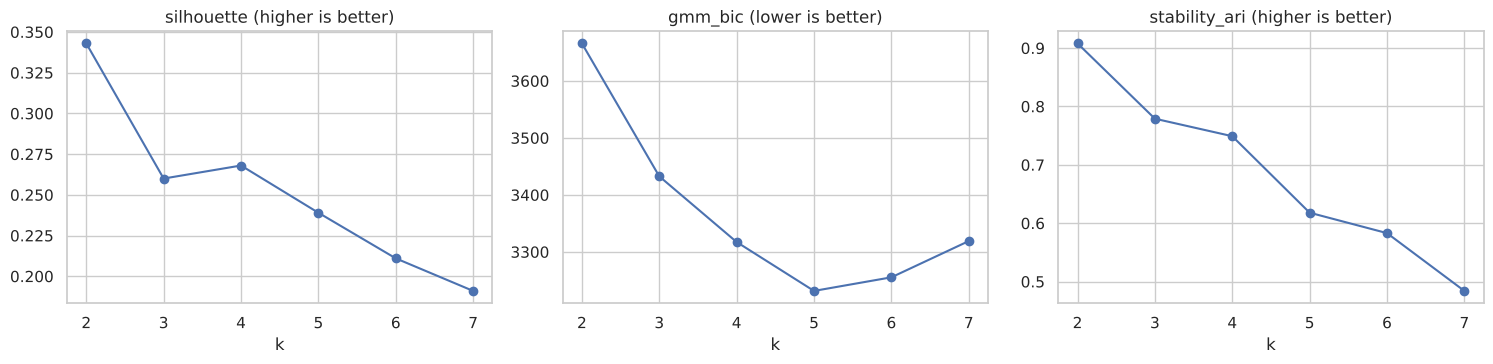

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, better in zip(axes, choice.columns, ["higher", "lower", "higher"]):
    ax.plot(choice.index, choice[col], marker="o")
    ax.set(title=f"{col} ({better} is better)", xlabel="k")
plt.tight_layout()
plt.show()

**Reading the three checks together:**
- **k=2** has the best silhouette and stability, but it only splits developed from developing countries. That's too coarse to target aid.
- **k=3 and k=4** both stay fairly stable (ARI ≈ 0.75–0.78). **Stability then collapses from k=5** (≈ 0.62 and falling), so groups beyond four are mostly noise.
- BIC keeps improving up to k=5, so a probabilistic model would accept more groups. But groups that change every time the data is resampled can't support a funding decision.

**I use k=3**: slightly more stable than k=4, simpler to explain, and each group has a clear interpretation.

## 3. The three groups

In [7]:
K = 3
km = KMeans(K, n_init=50, random_state=SEED).fit(Z)
df["cluster"] = km.labels_

# Name clusters by their median child mortality so labels are reproducible
order = df.groupby("cluster")["child_mort"].median().sort_values(ascending=False).index
names = dict(zip(order, ["High need", "Developing", "Developed"]))
df["group"] = df["cluster"].map(names)

profile = df.groupby("group")[["child_mort", "life_expec", "total_fer", "income", "gdpp", "health", "inflation"]].median()
profile.insert(0, "countries", df["group"].value_counts())
profile.loc[["High need", "Developing", "Developed"]].round(1)

,countries,child_mort,life_expec,total_fer,income,gdpp,health,inflation
group,,,,,,,,
High need,49,88.2,60.7,5.0,1870.0,758.0,5.3,7.6
Developing,68,19.2,73.2,2.4,10180.0,4850.0,5.3,7.6
Developed,50,4.7,80.0,1.6,29150.0,27450.0,9.0,1.1


PC1 explains 55%, PC2 17%


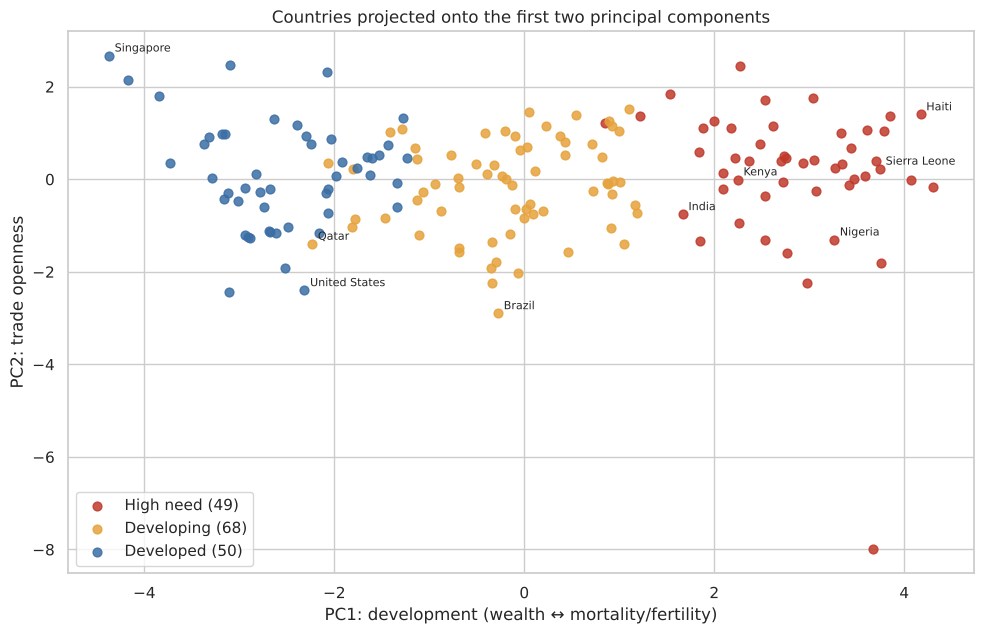

,PC1,PC2
child_mort,0.43,0.08
exports,-0.24,0.54
health,-0.14,0.09
imports,-0.10,0.76
income,-0.42,-0.14
inflation,0.24,-0.18
life_expec,-0.40,-0.19
total_fer,0.39,0.11
gdpp,-0.42,-0.12


In [8]:
pca = PCA(2, random_state=SEED).fit(Z)
pcs = pca.transform(Z)
print(f"PC1 explains {pca.explained_variance_ratio_[0]:.0%}, PC2 {pca.explained_variance_ratio_[1]:.0%}")
loadings = pd.DataFrame(pca.components_.T, index=features.columns, columns=["PC1", "PC2"]).round(2)

palette = {"High need": "#c0392b", "Developing": "#e6a23c", "Developed": "#3b6ea5"}
fig, ax = plt.subplots(figsize=(10, 6.5))
for g, col in palette.items():
    m = df["group"] == g
    ax.scatter(pcs[m, 0], pcs[m, 1], s=40, color=col, label=f"{g} ({m.sum()})", alpha=0.85)
for country in ["Kenya", "Nigeria", "India", "United States", "Qatar", "Haiti", "Brazil", "Sierra Leone", "Singapore"]:
    if country in df.index:
        i = df.index.get_loc(country)
        ax.annotate(country, pcs[i], fontsize=8, xytext=(4, 3), textcoords="offset points")
ax.set(xlabel="PC1: development (wealth ↔ mortality/fertility)", ylabel="PC2: trade openness",
       title="Countries projected onto the first two principal components")
ax.legend()
plt.tight_layout()
plt.show()
loadings

PC1 is the development axis: high income and life expectancy on one side, high child mortality and fertility on the other. The three groups line up along it cleanly. PC2 (trade) separates countries *within* groups but doesn't drive the split.

## 4. From cluster to priority list

The clusters say *which* countries are in need. They don't say *who first*. To rank inside the high-need group, I build a simple **need index**: the average of each country's percentile rank on five indicators, oriented so higher always means greater need:

| Indicator | Direction |
|---|---|
| child mortality | higher = more need |
| life expectancy | lower = more need |
| income per person | lower = more need |
| GDP per capita | lower = more need |
| health spending (% GDP) | lower = more need |

Percentile ranks are robust to outliers and easy to explain to a non-technical funder.

In [9]:
need = pd.DataFrame({
    "child_mort": df["child_mort"].rank(pct=True),
    "life_expec": 1 - df["life_expec"].rank(pct=True),
    "income": 1 - df["income"].rank(pct=True),
    "gdpp": 1 - df["gdpp"].rank(pct=True),
    "health": 1 - df["health"].rank(pct=True),
})
df["need_index"] = (need.mean(axis=1) * 100).round(1)

priority = (df[df["group"] == "High need"]
            .sort_values("need_index", ascending=False)
            [["need_index", "child_mort", "life_expec", "income", "gdpp", "health"]])
print(f"{len(priority)} high-need countries. Top 15 by need index:")
priority.head(15)

49 high-need countries. Top 15 by need index:


,need_index,child_mort,life_expec,income,gdpp,health
country,,,,,,
Central African Republic,95.1,149.0,47.5,888,446,3.98
Niger,89.5,123.0,58.8,814,348,5.16
Mozambique,88.9,101.0,54.5,918,419,5.21
Guinea,87.7,109.0,58.0,1190,648,4.93
Chad,87.4,150.0,56.5,1930,897,4.53
Madagascar,87.2,62.2,60.8,1390,413,3.77
Eritrea,86.6,55.2,61.7,1420,482,2.66
Benin,85.8,111.0,61.8,1820,758,4.10
Mali,85.6,137.0,59.5,1870,708,4.98


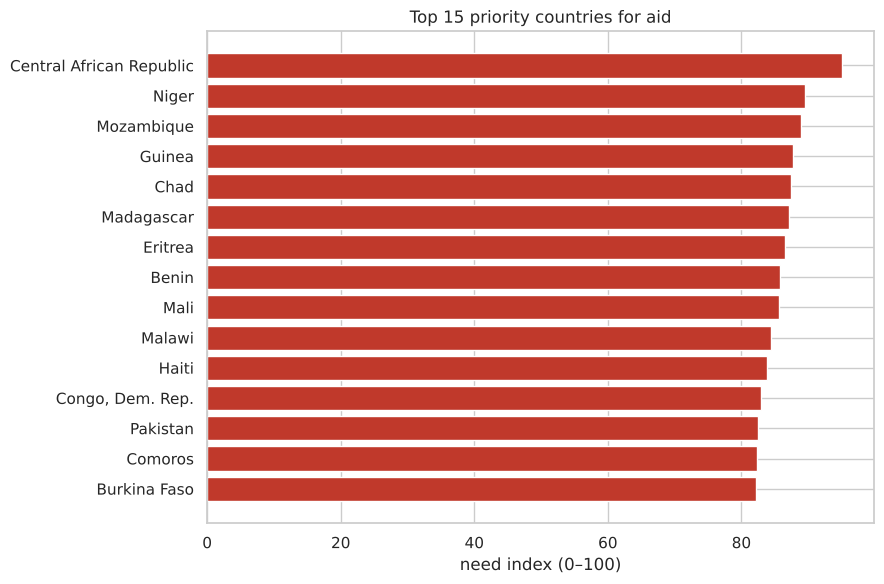

In [10]:
top = priority.head(15).iloc[::-1]
plt.figure(figsize=(9, 6))
plt.barh(top.index, top["need_index"], color="#c0392b")
plt.xlabel("need index (0–100)")
plt.title("Top 15 priority countries for aid")
plt.tight_layout()
plt.show()

## 5. Sanity checks

In [11]:
print("Is the ranking driven by one indicator? Correlation of each component with the index (high-need group):")
print(need.loc[priority.index].corrwith(priority["need_index"]).round(2).to_string())

gmm = GaussianMixture(K, covariance_type="diag", n_init=10, random_state=SEED).fit(Z)
agree = adjusted_rand_score(km.labels_, gmm.predict(Z))
print(f"\nAgreement between K-Means and a Gaussian mixture on the same data (ARI): {agree:.2f}")

if "Kenya" in df.index:
    print(f"\nKenya: group = {df.loc['Kenya', 'group']}, need index = {df.loc['Kenya', 'need_index']}")

Is the ranking driven by one indicator? Correlation of each component with the index (high-need group):
child_mort    0.62
life_expec    0.49
income        0.32
gdpp          0.54
health        0.58

Agreement between K-Means and a Gaussian mixture on the same data (ARI): 0.75

Kenya: group = High need, need index = 78.7


## Takeaways

- **Log-transforming skewed indicators before clustering** gave much cleaner groups than scaling raw values.
- **Three groups** was the finest split that stayed stable under resampling and agreed with a different algorithm (Gaussian mixture).
- The **high-need group is concentrated in sub-Saharan Africa**, with child mortality many times higher and life expectancy far lower than in developed countries.
- The **need index** turns a cluster label into an ordered shortlist a funder can act on and audit. Each country's score comes from five percentile ranks that anyone can check.
- **Limitation:** the indicators are a single snapshot and don't capture conflict, disasters or existing aid flows, all of which a real allocation decision would weigh.